### Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "paths.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate project root containing src/paths.py")
sys.path.insert(0, str(ROOT))

from src.paths import *
from src.nasa_power import download_nasa_power

### Load solar plants

In [2]:
solar_plants_path = GIS / "solar_power_plants.csv"
if solar_plants_path.is_file():
    solar_plants = pd.read_csv(solar_plants_path)
    display(solar_plants)
else:
    print(f"Solar plant input is missing: {solar_plants_path}")
    print(f"Fill datasets/templates/solar_plants_template.csv and save the completed file as {solar_plants_path.name} in {GIS}.")
    solar_plants = pd.DataFrame(columns=["plant_id", "latitude", "longitude"])

,plant_id,name,bus_id,latitude,longitude,capacity_mw
0,SOL_01,Siyambalanduwa Solar Park,MONARAGALA,6.875,81.345,100
1,SOL_02,Hambantota Solar Park,HAMBANTOTA,6.140,81.120,10
2,SOL_03,Buruthakanda Solar,HAMBANTOTA,6.175,81.150,10
3,SOL_04,Welikanda Solar,VALACHCHENAI,7.950,81.250,10
4,SOL_05,Vavunathivu Solar,AMPARA,7.680,81.650,10
5,SOL_06,Colombo Commercial Solar Cluster,PANNIPITIYA,6.845,79.955,50
6,SOL_07,Trincomalee Solar Park,TRINCOMALEE,8.587,81.215,50
7,SOL_08,Kurunegala Solar Farm,KURUNEGALA,7.485,80.365,20
8,SOL_09,Kilinochchi Solar Farm,KILINOCHCHI,9.395,80.405,20
9,SOL_10,Anuradhapura Solar Farm,NEW_ANURADHAPURA,8.325,80.425,20


### Download NASA POWER data

In [3]:
START_DATE = "20240101"
END_DATE = "20241231"

if solar_plants.empty:
    print("NASA POWER download skipped: no populated solar plant coordinates are available.")

for _, plant in solar_plants.iterrows():

    plant_id = str(plant["plant_id"])

    output_file = (
        NASA / f"{plant_id}_hourly.csv"
    )

    if output_file.exists():
        print("Already downloaded:", plant_id)
        continue

    try:
        df = download_nasa_power(
            latitude=float(plant["latitude"]),
            longitude=float(plant["longitude"]),
            start_date=START_DATE,
            end_date=END_DATE,
            output_path=output_file
        )
        print(f"Downloaded {plant_id}")
    except Exception as exc:
        print(f"Notice: Online fetch skipped for {plant_id} ({exc}). Using cached solar files.")


Already downloaded: SOL_01
Already downloaded: SOL_02
Already downloaded: SOL_03
Already downloaded: SOL_04
Already downloaded: SOL_05
Already downloaded: SOL_06
Already downloaded: SOL_07
Already downloaded: SOL_08
Already downloaded: SOL_09
Already downloaded: SOL_10


### Inspect solar irradiance

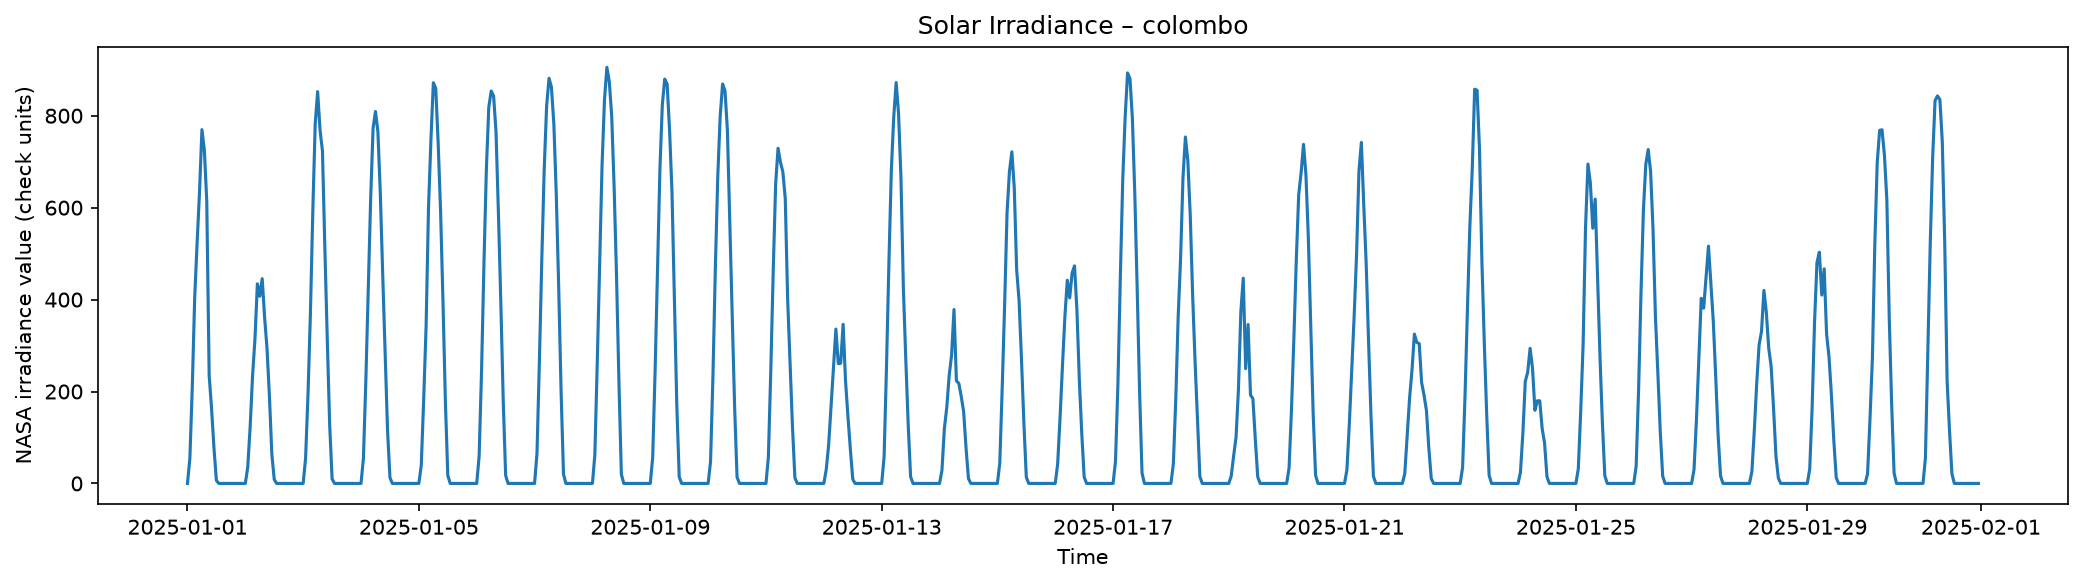

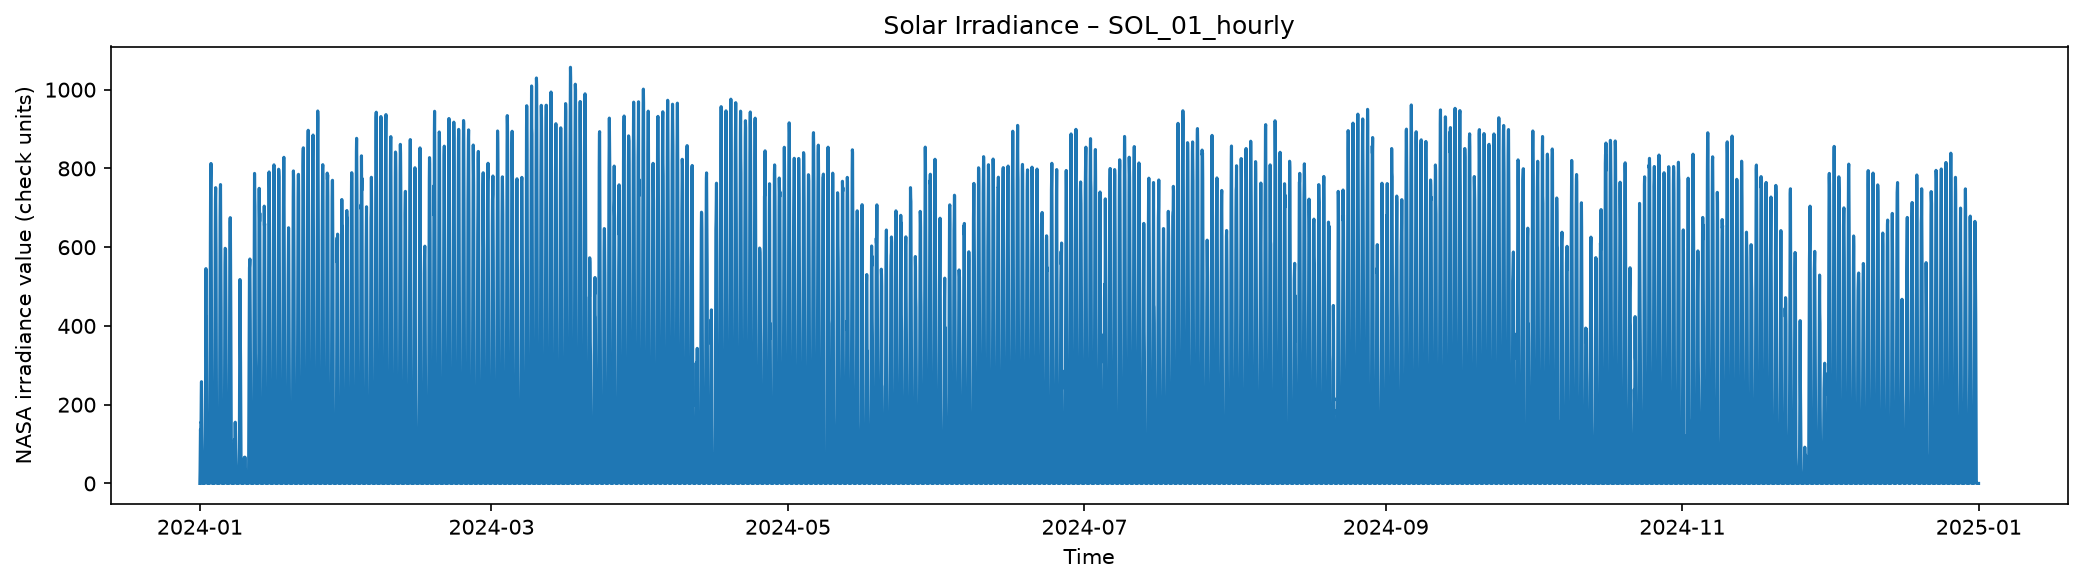

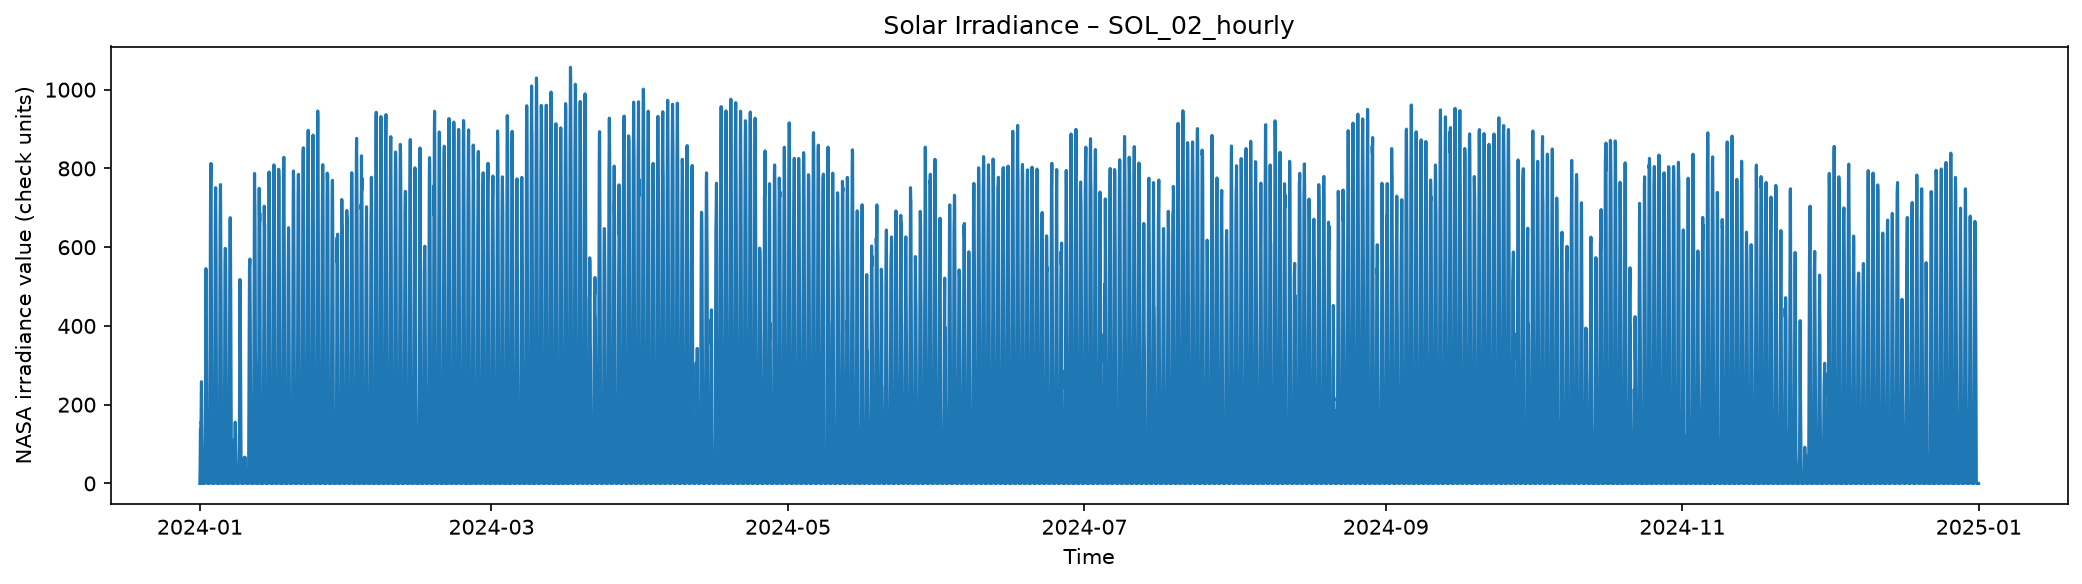

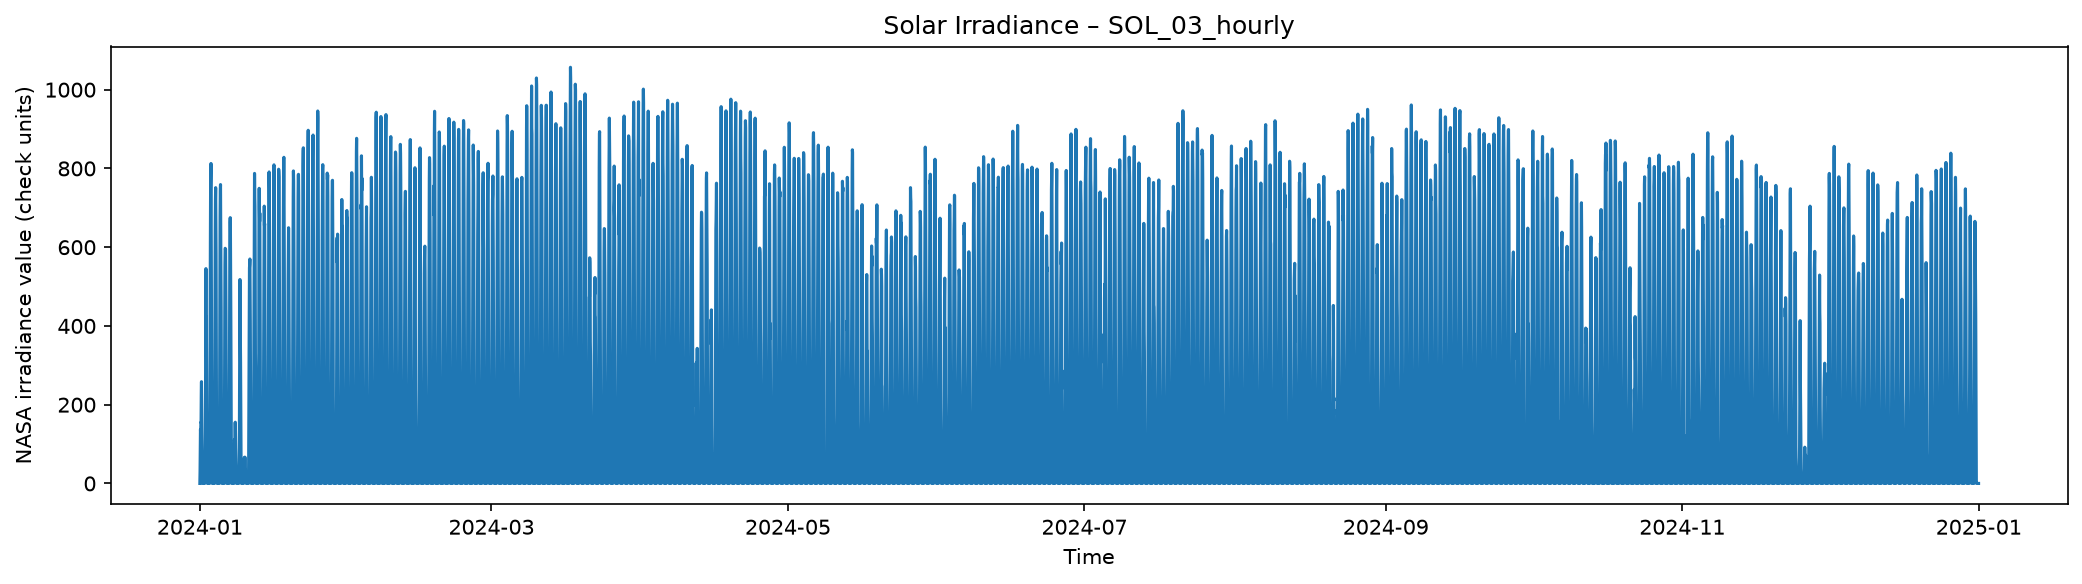

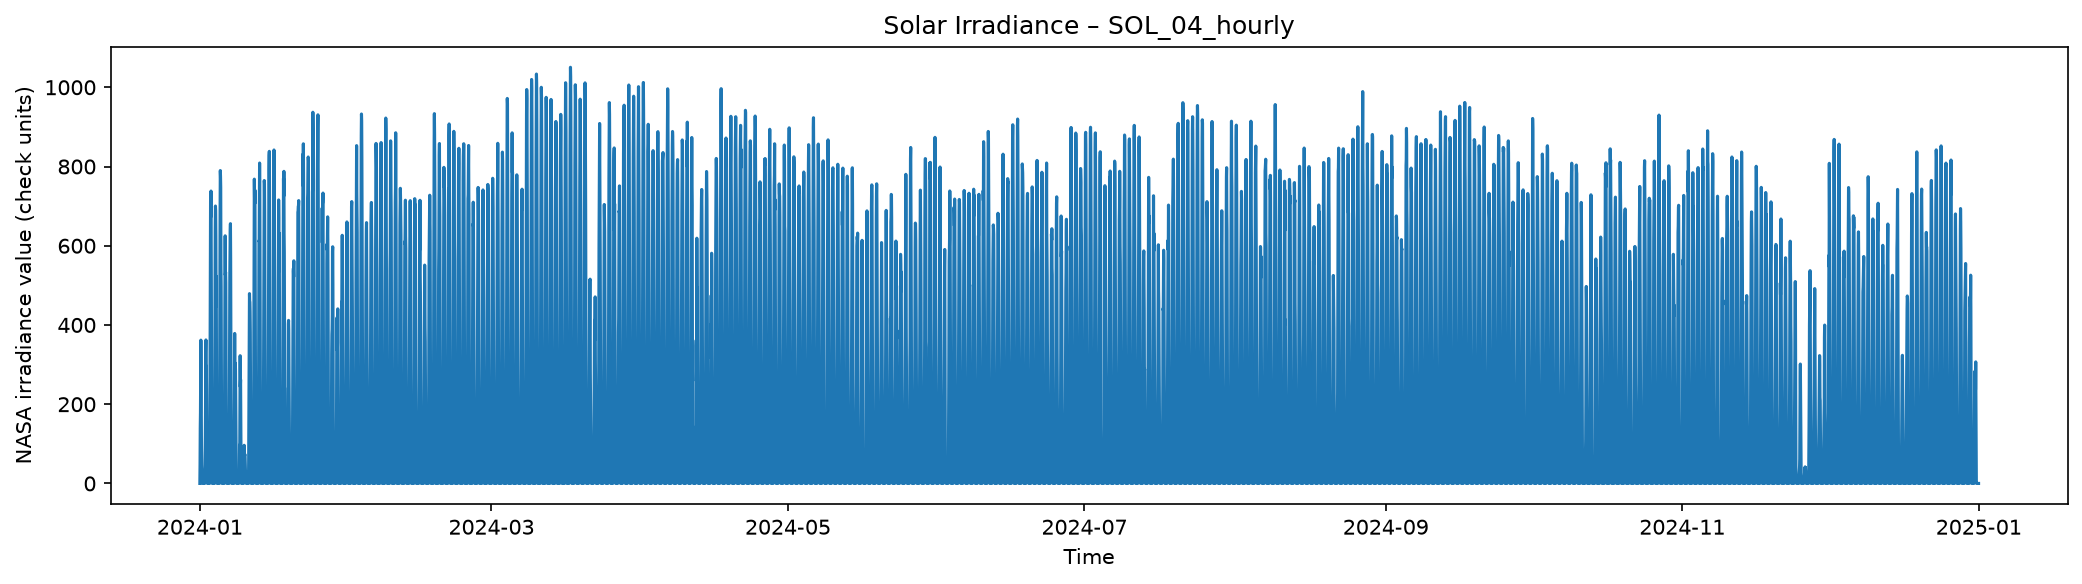

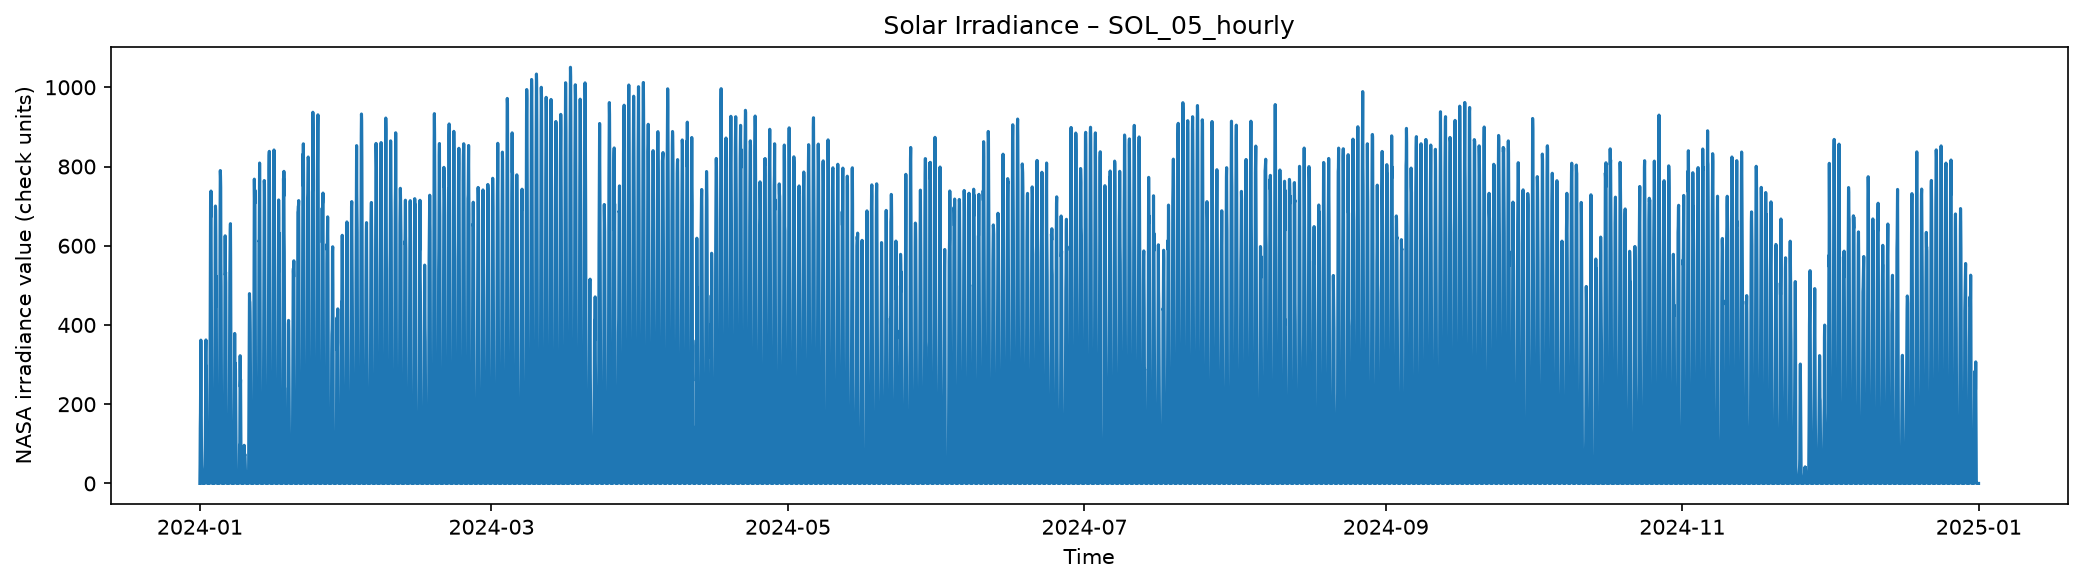

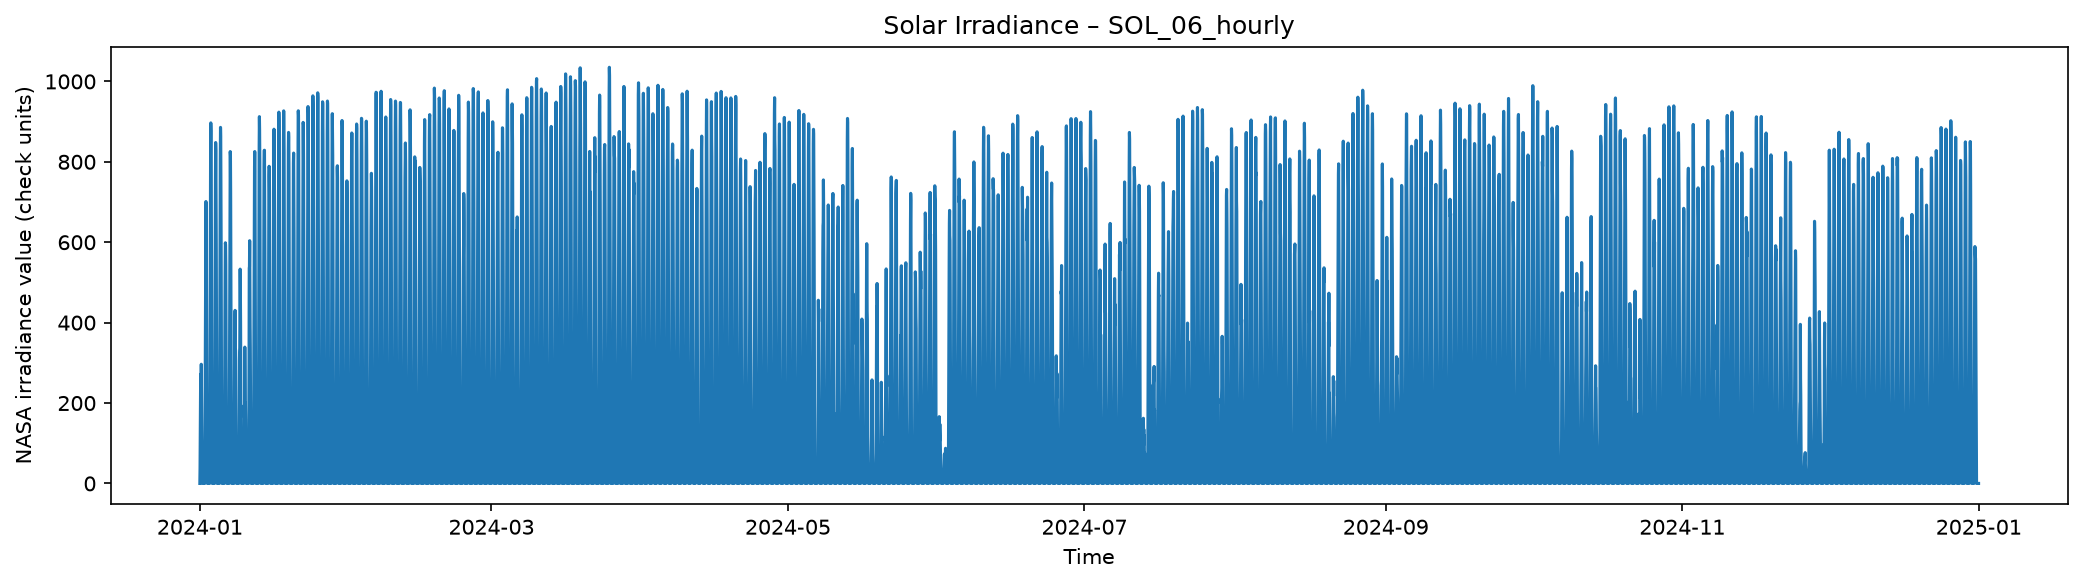

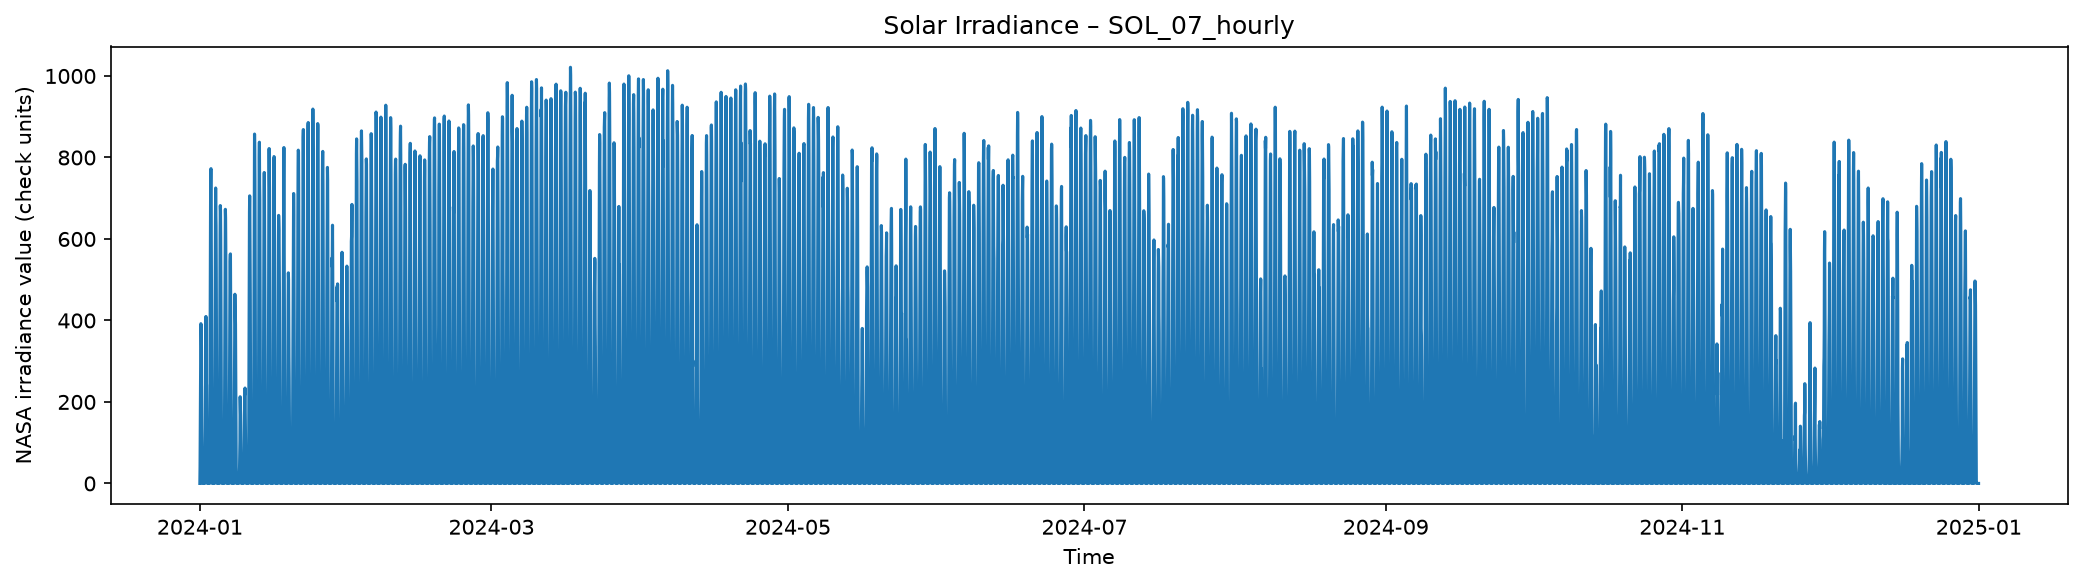

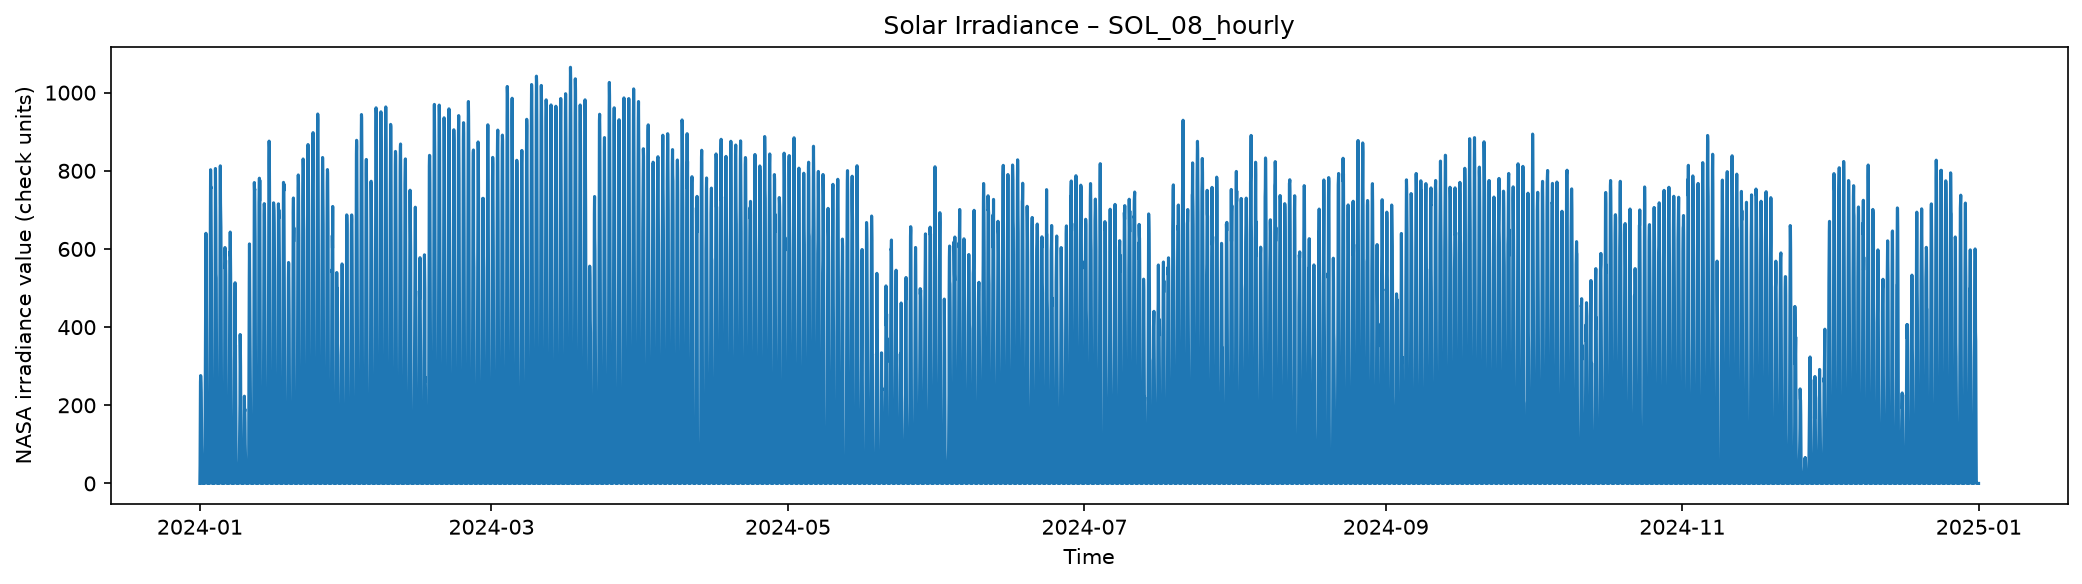

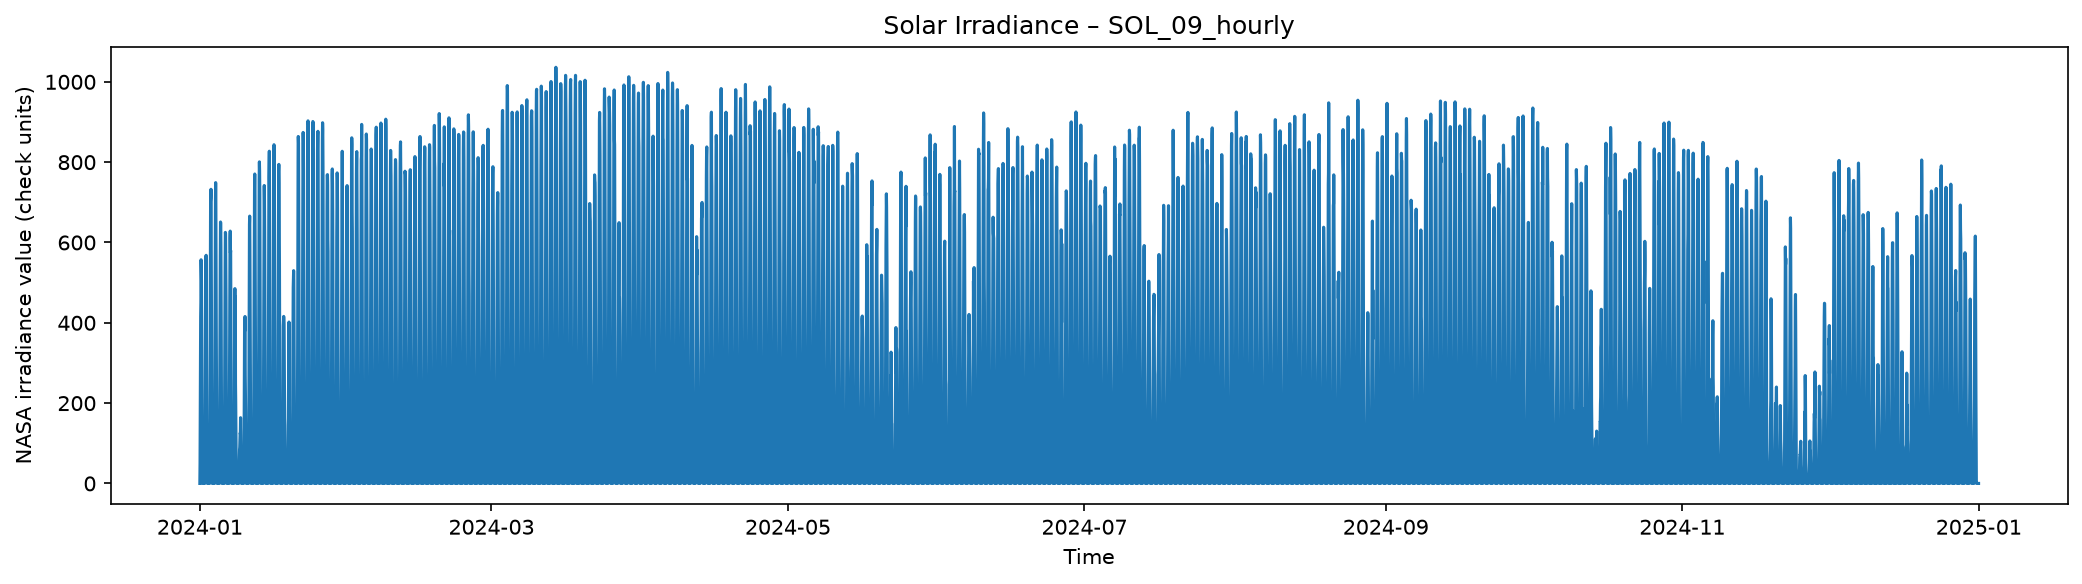

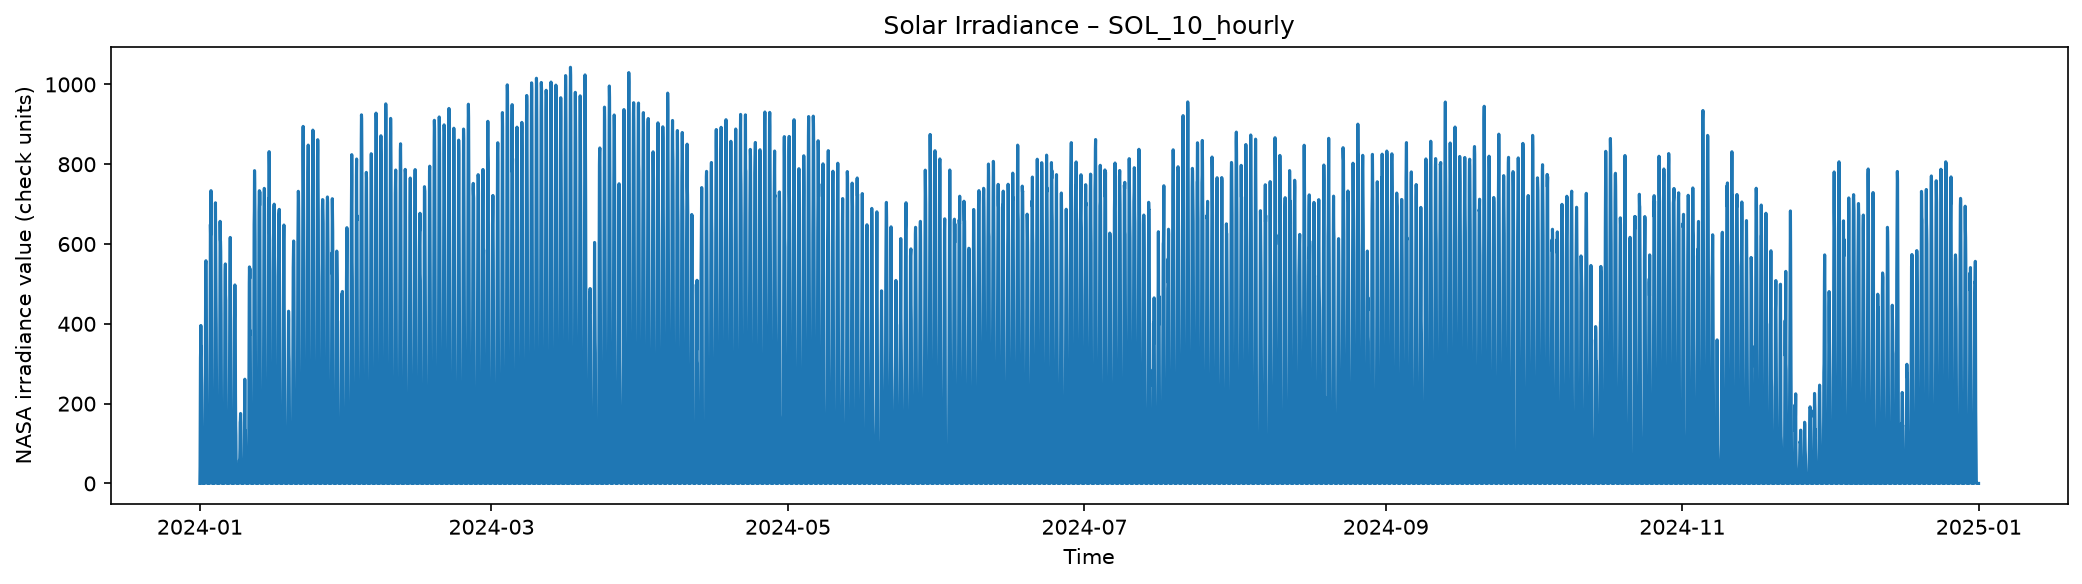

In [4]:
files = sorted([f for f in NASA.glob("*.csv") if f.is_file()])
if not files:
    print(f"No NASA hourly files found in {NASA}. Populate the solar plant input and run the download cell first.")


for file in files:

    df = pd.read_csv(file)

    df["timestamp"] = pd.to_datetime(df["timestamp"])

    plt.figure(figsize=(14, 4))

    plt.plot(
        df["timestamp"],
        df["solar_irradiance"]
    )

    plt.title(f"Solar Irradiance – {file.stem}")
    plt.xlabel("Time")
    plt.ylabel("NASA irradiance value (check units)")
    plt.tight_layout()


### Daily solar resource analysis

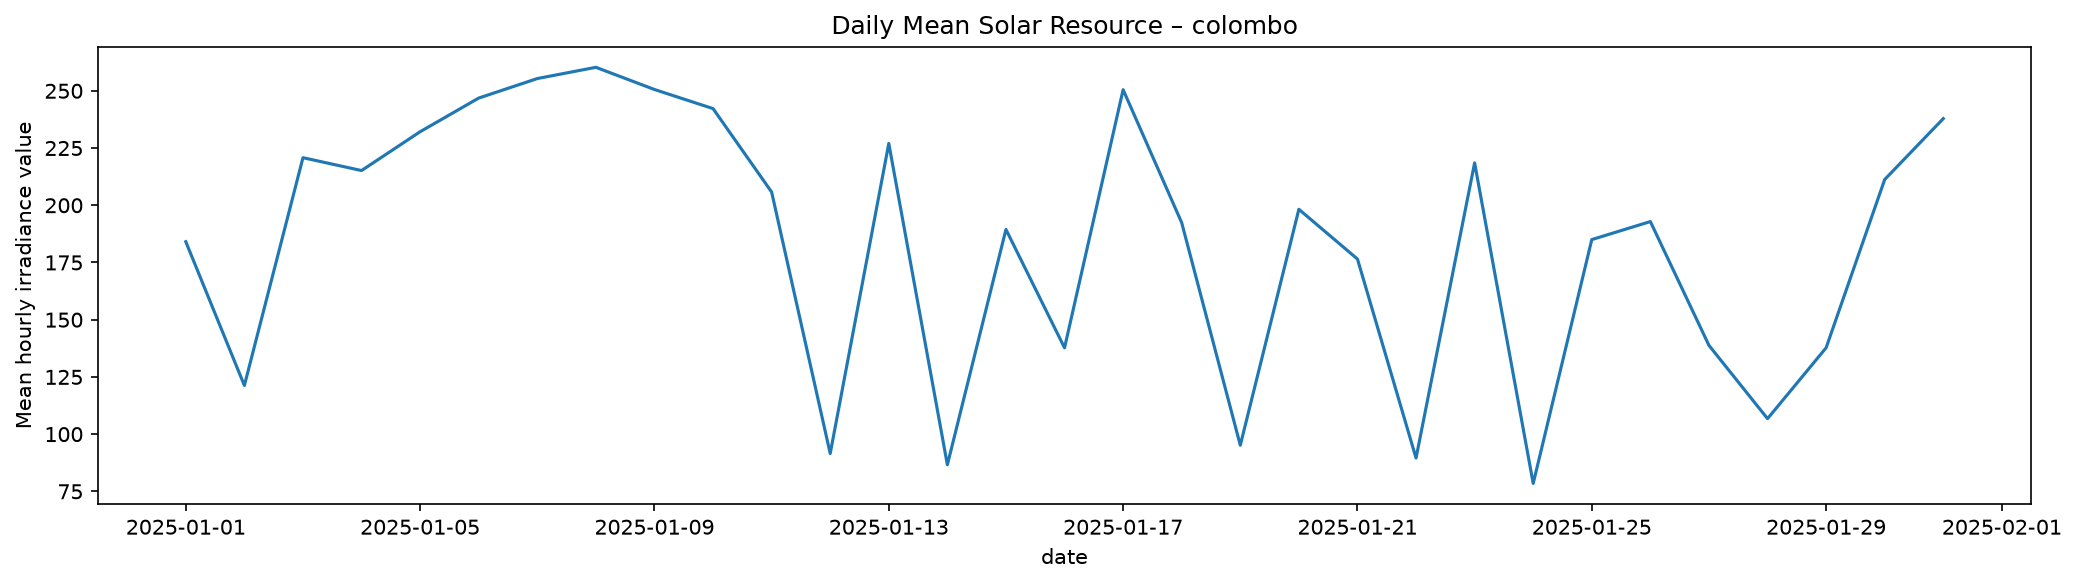

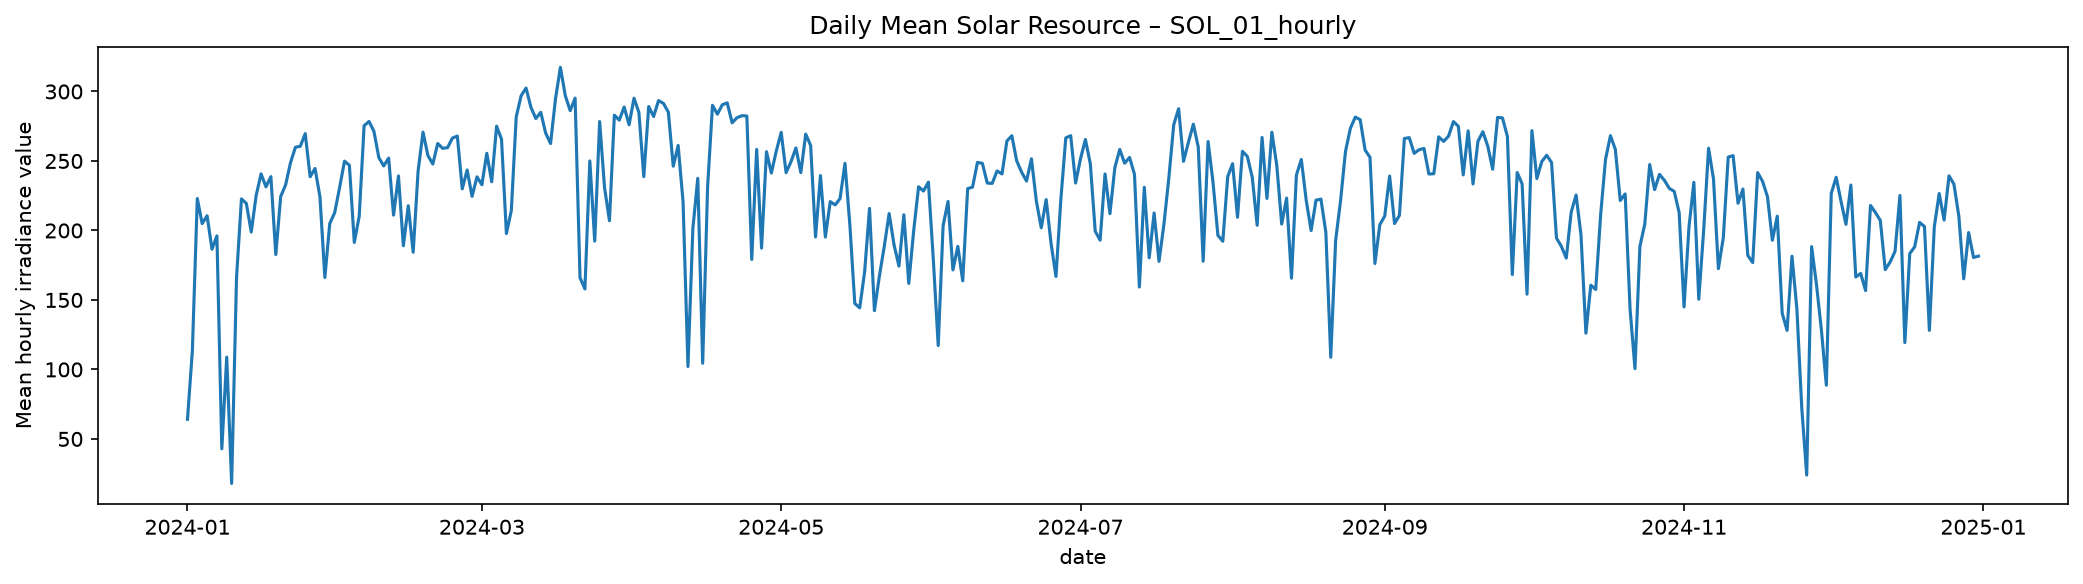

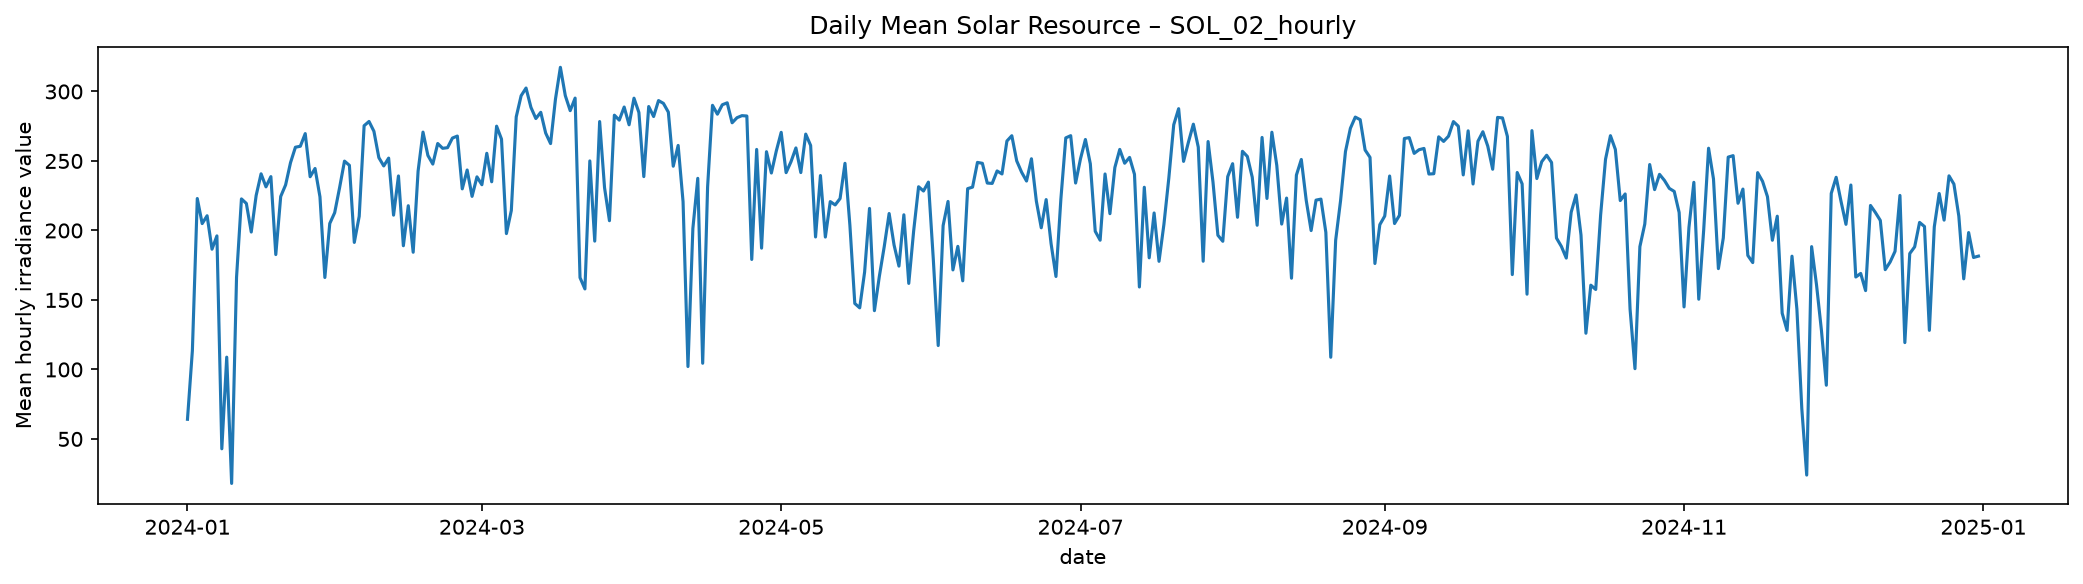

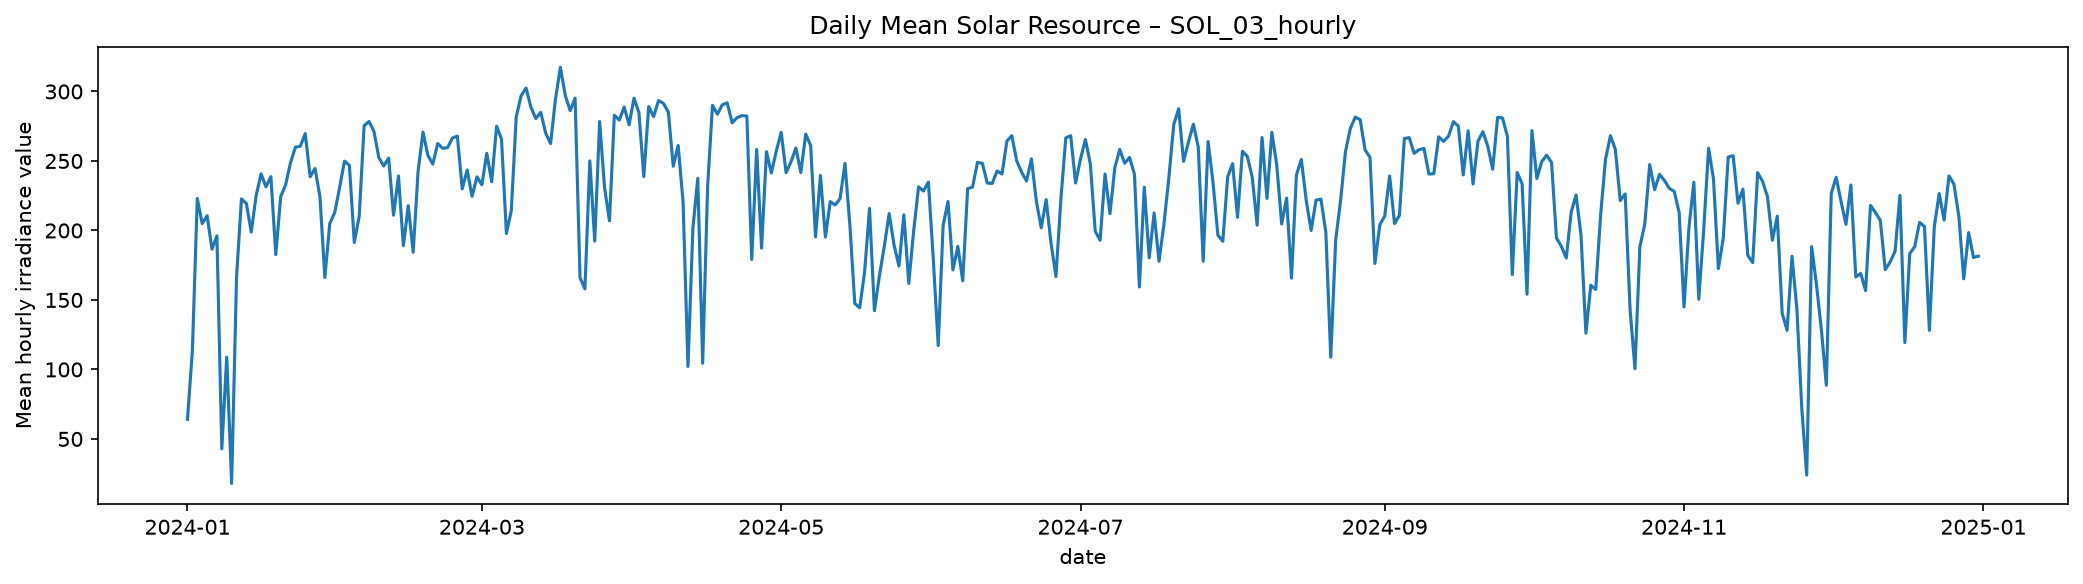

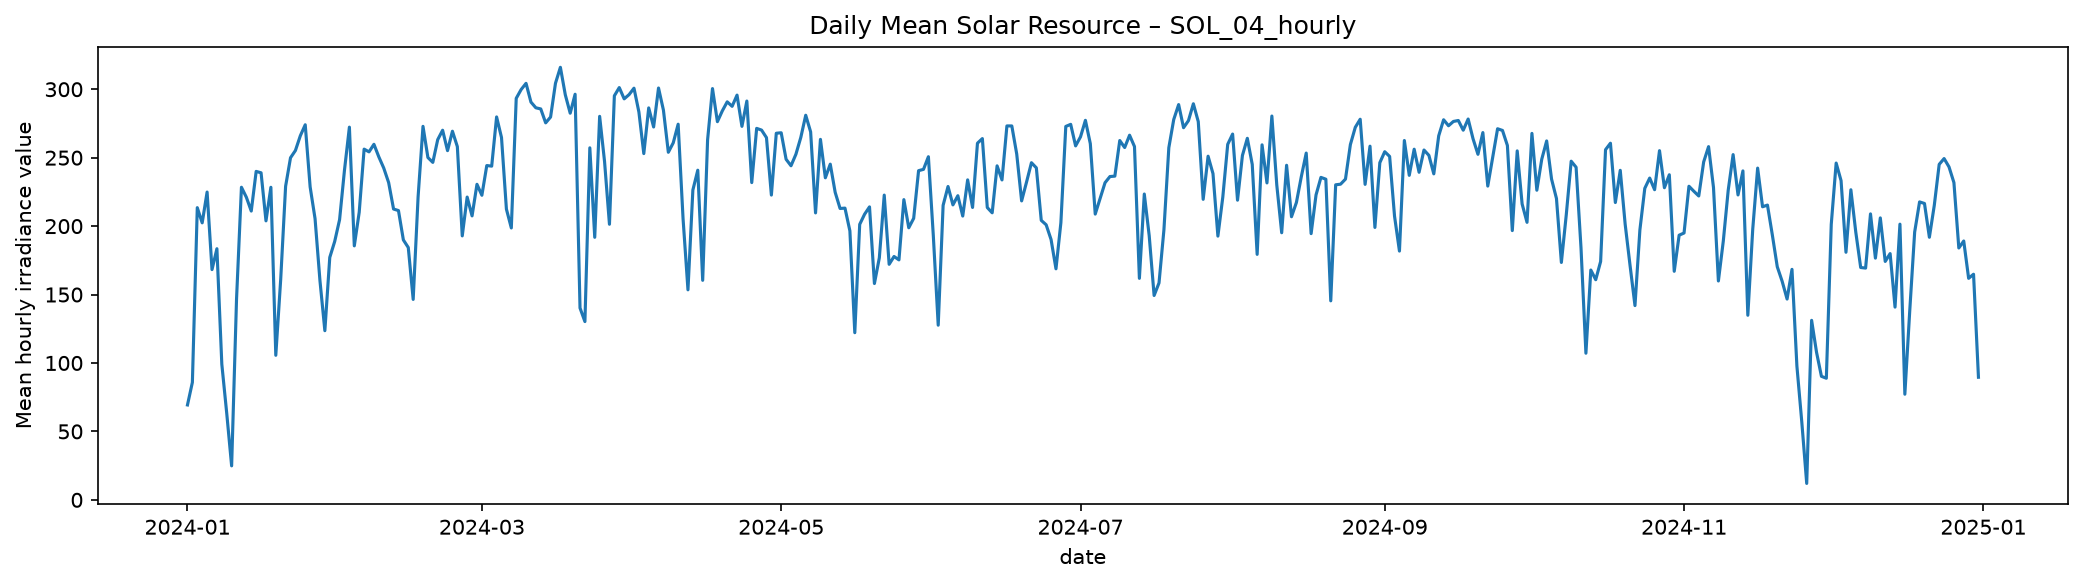

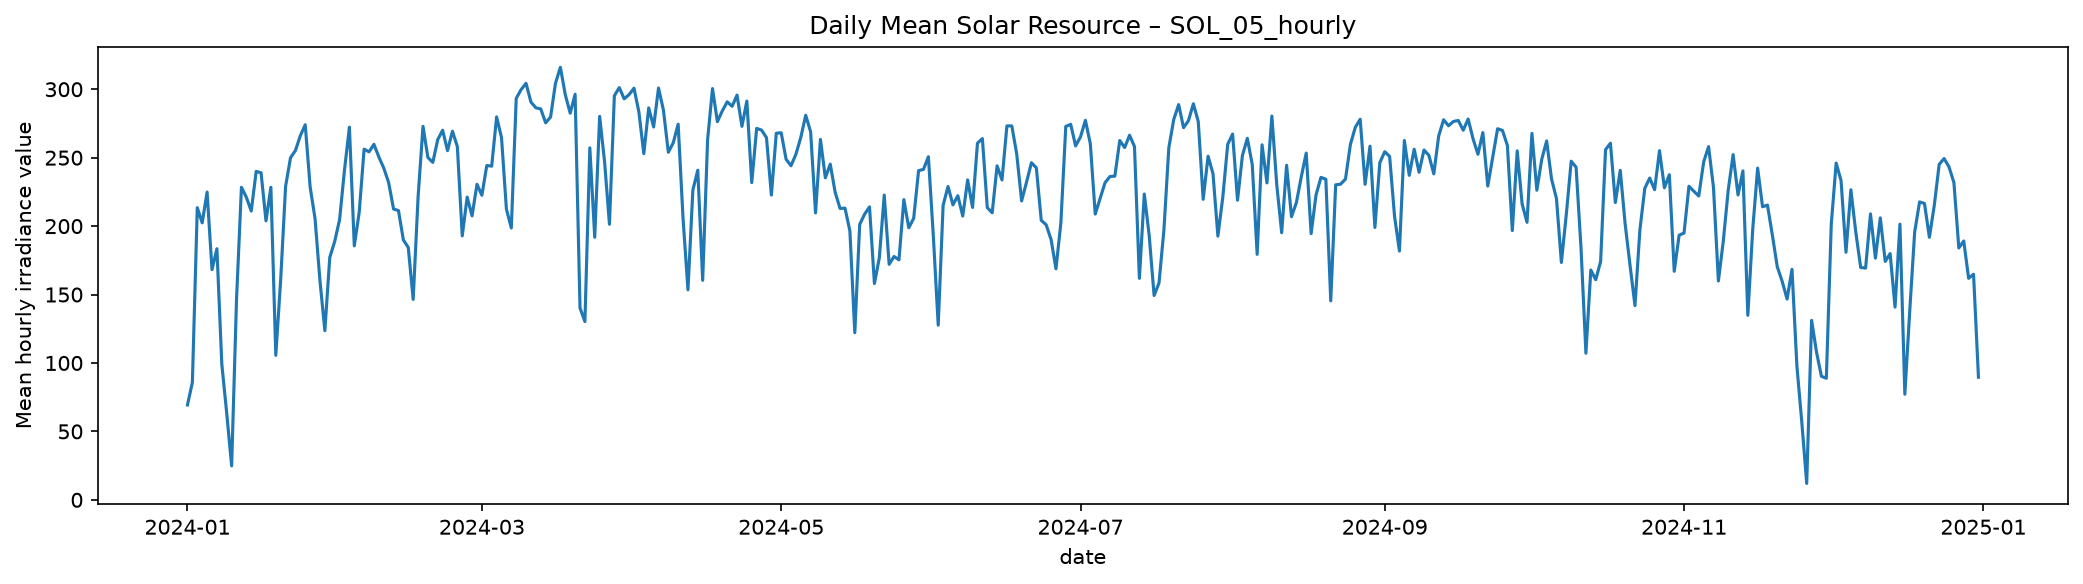

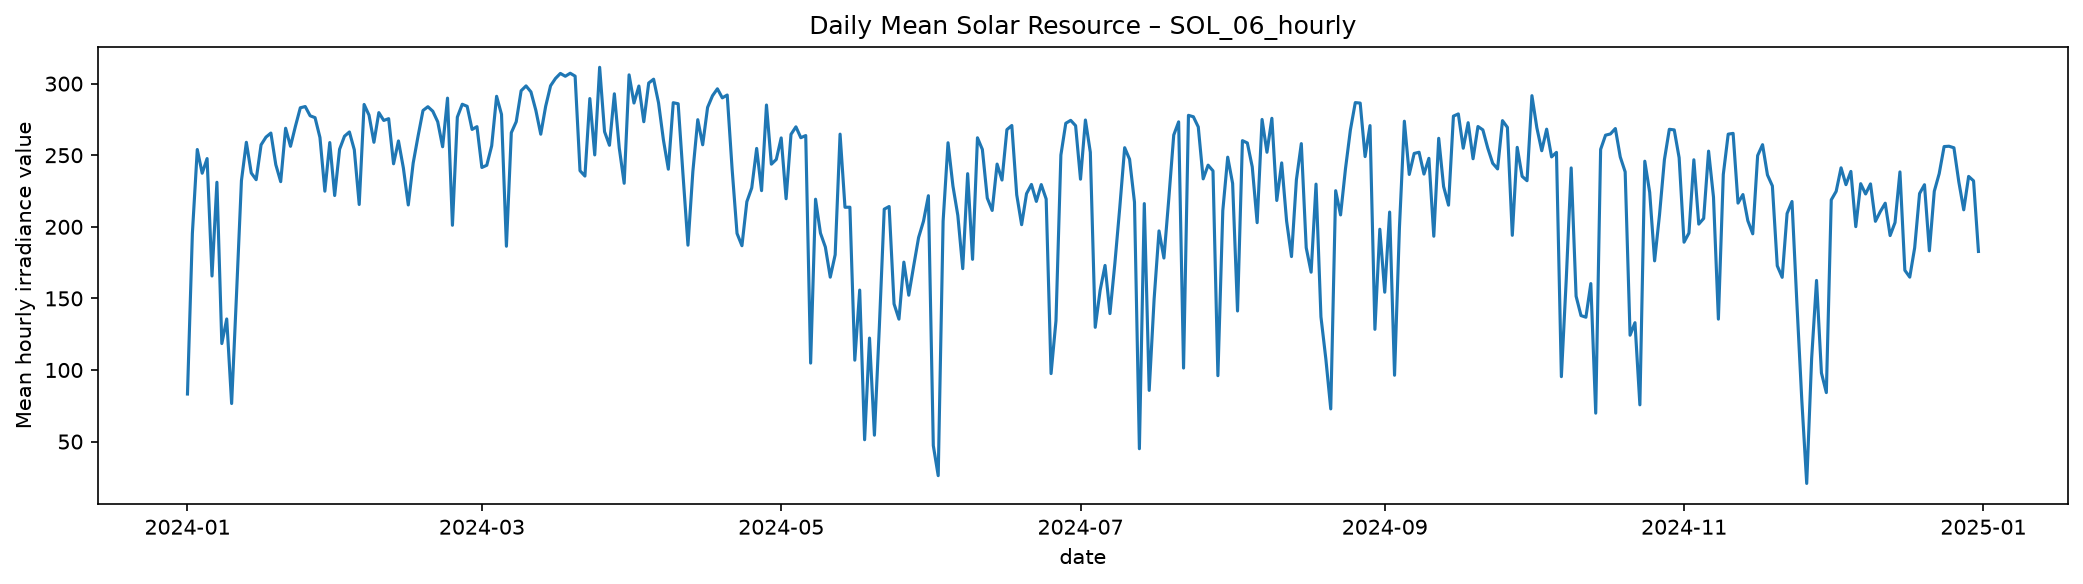

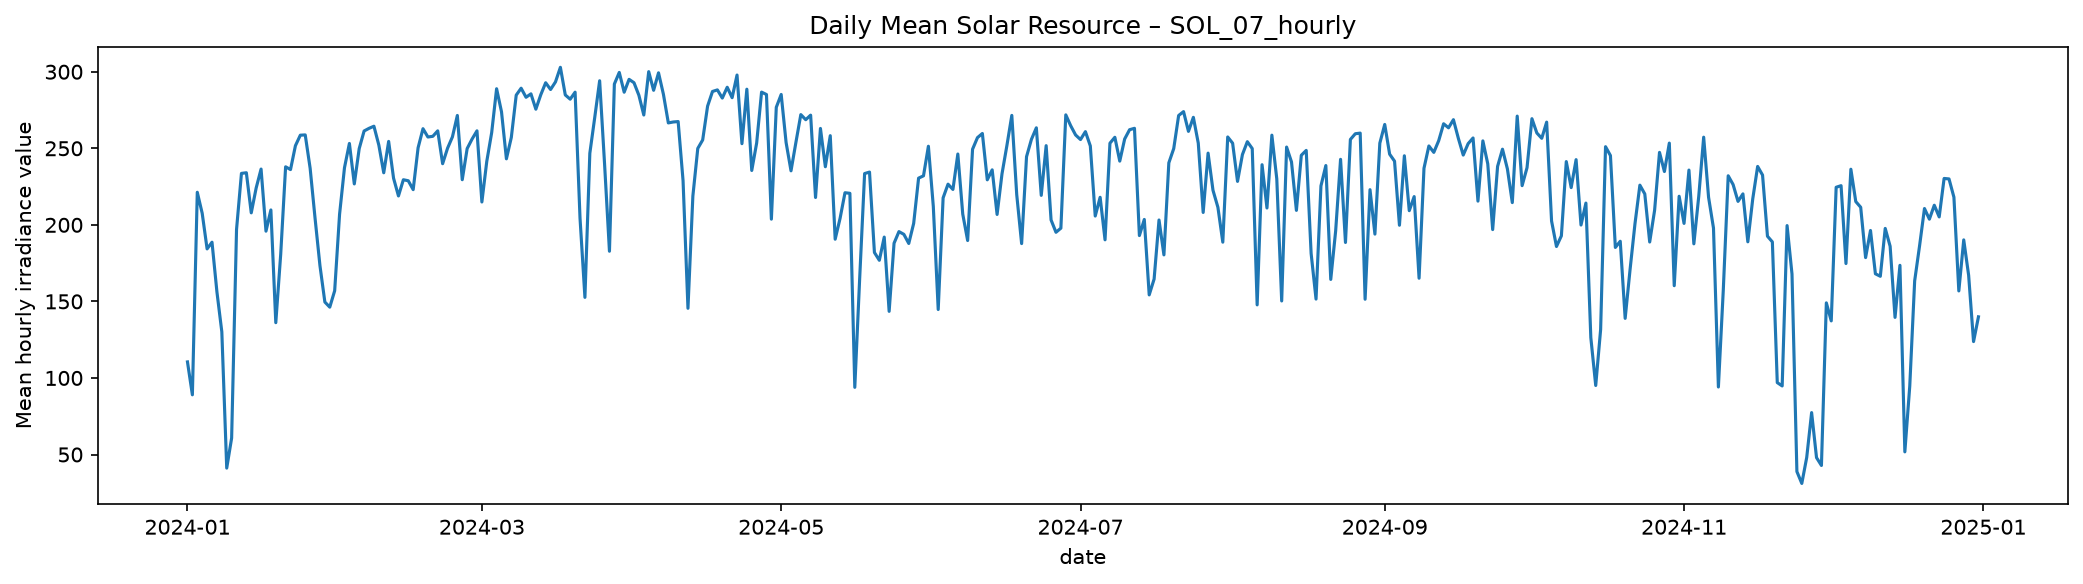

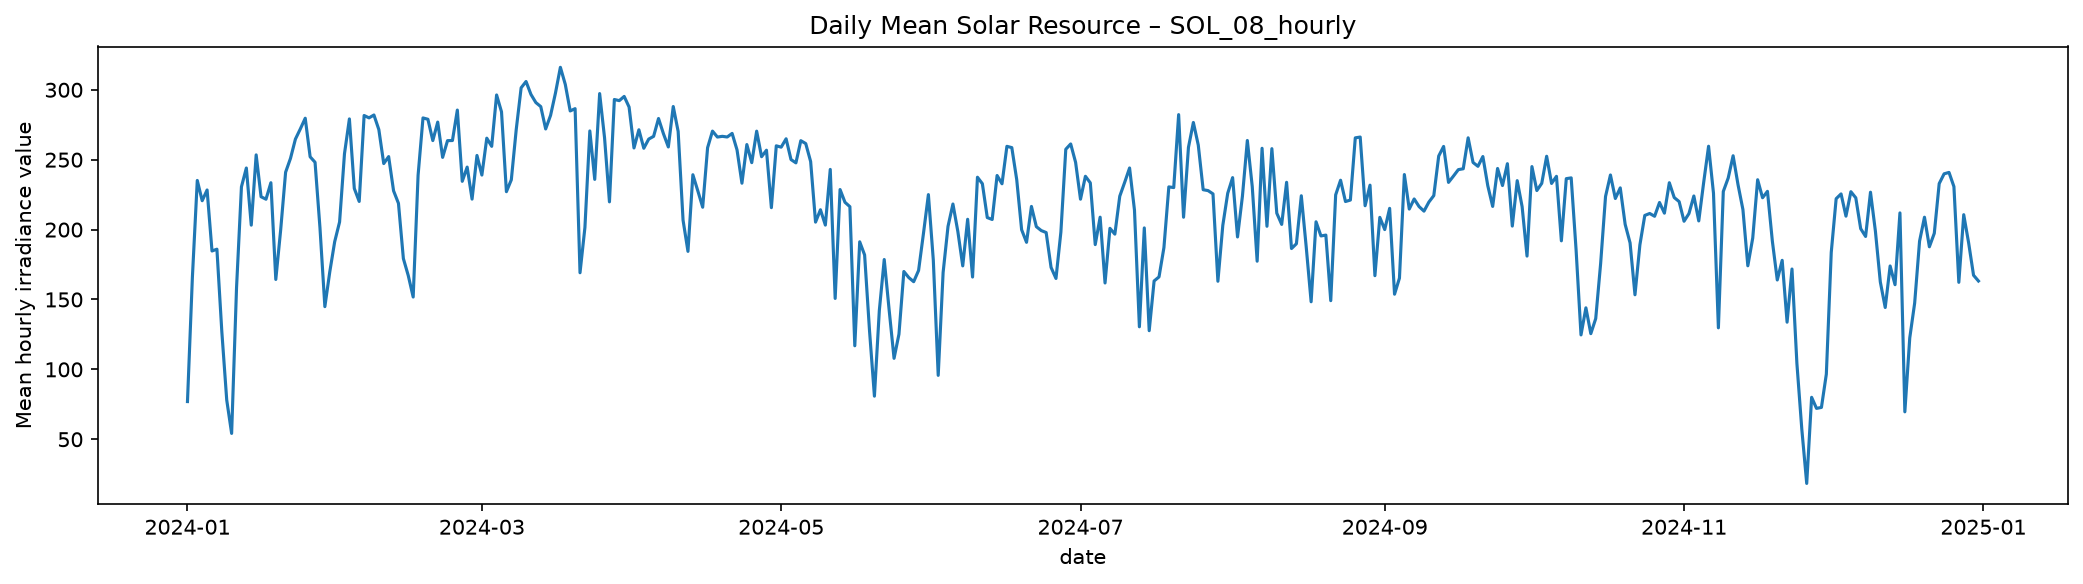

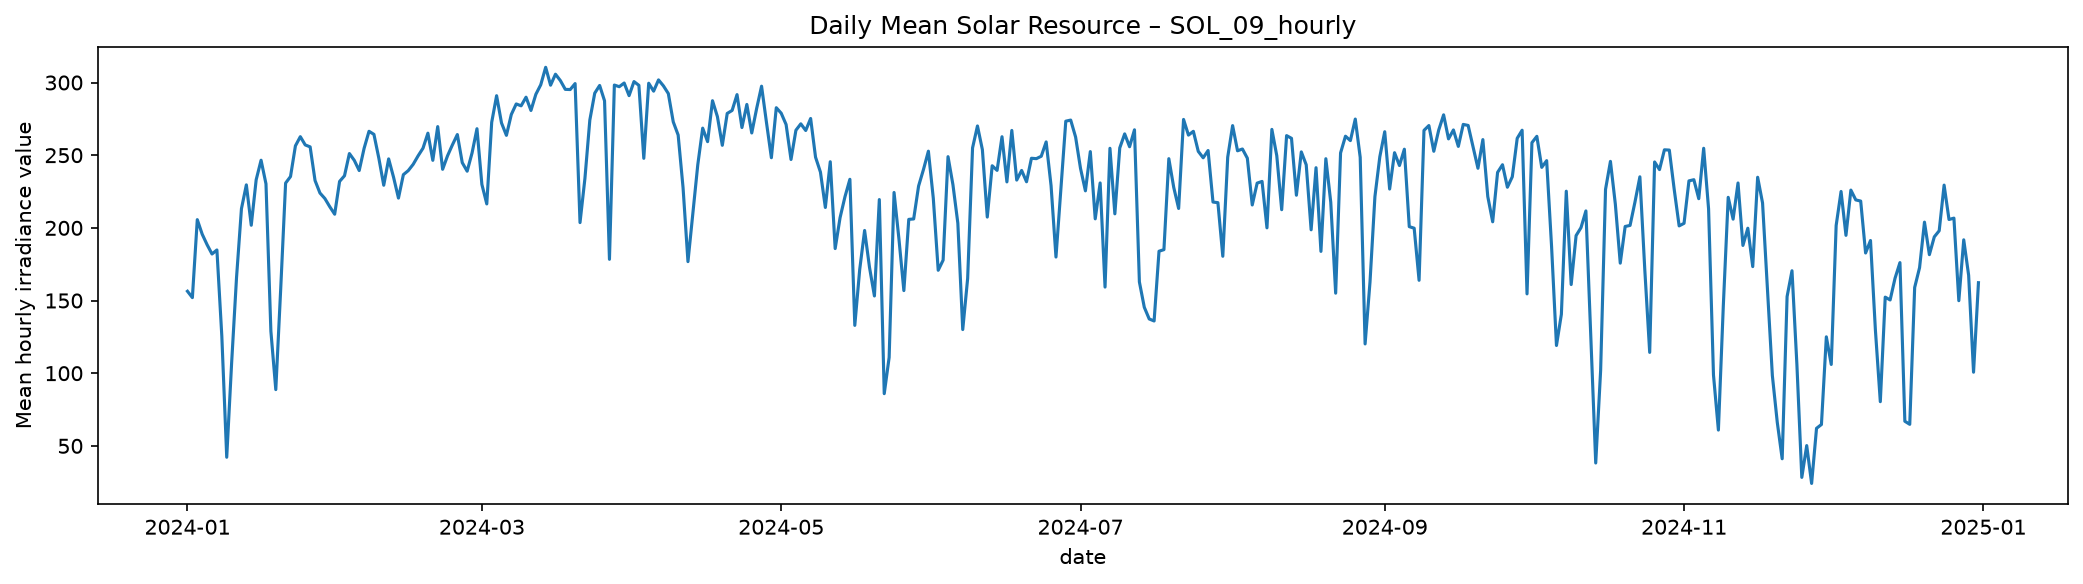

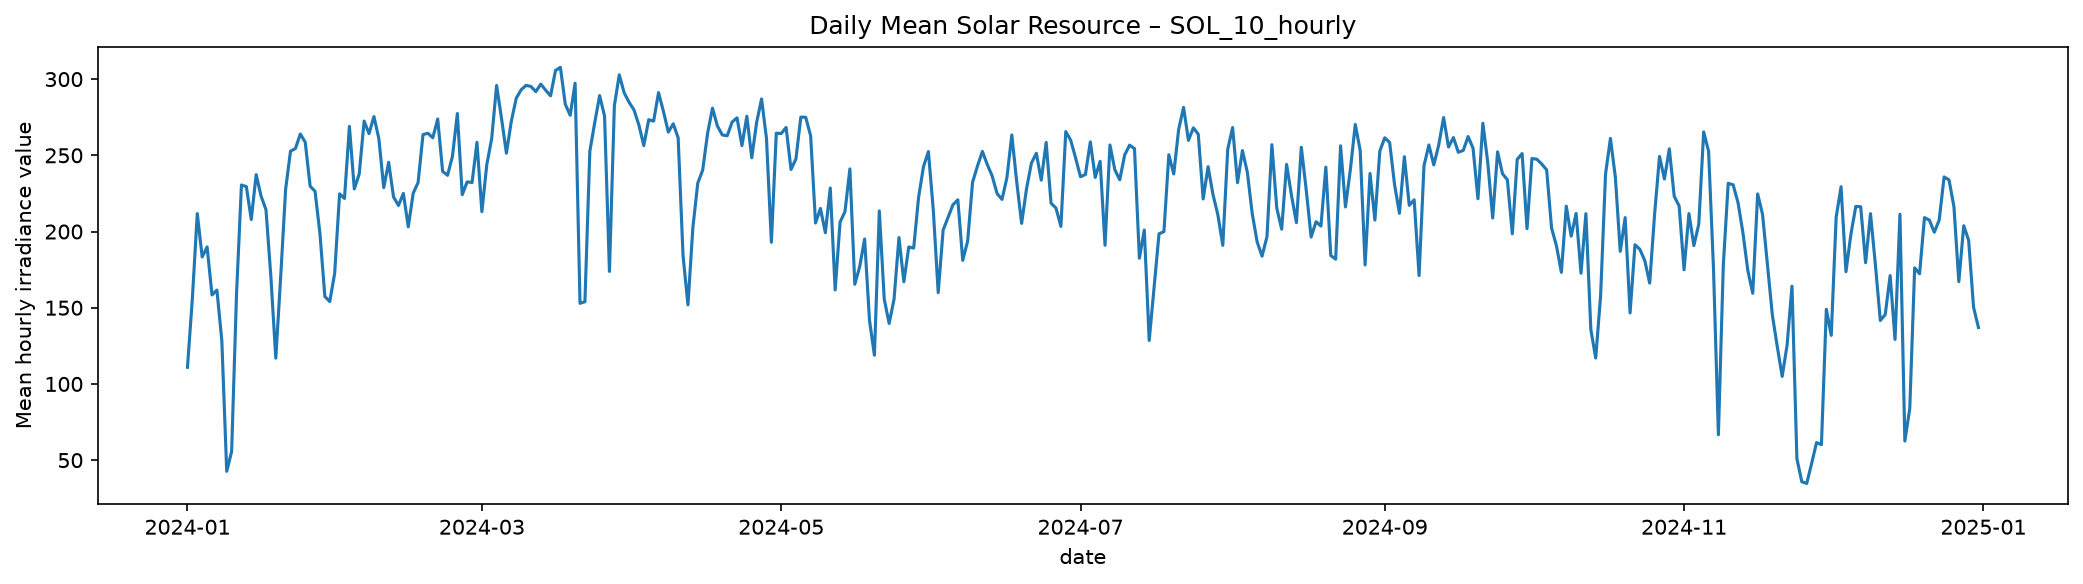

In [5]:
for file in files:

    df = pd.read_csv(file)

    df["timestamp"] = pd.to_datetime(df["timestamp"])

    df["date"] = df["timestamp"].dt.date

    daily = df.groupby("date")[
        "solar_irradiance"
    ].mean()

    daily.plot(
        figsize=(14, 4),
        title=f"Daily Mean Solar Resource – {file.stem}"
    )

    plt.ylabel("Mean hourly irradiance value")
    plt.tight_layout()
    plt.show()